Maximum Profit (DP): 220
Maximum Profit (B&B): 220

n = 5: DP = 186, B&B = 186

n = 10: DP = 445, B&B = 445

n = 15: DP = 585, B&B = 585

n = 20: DP = 627, B&B = 627

n = 25: DP = 597, B&B = 597

Items | DP Time    | B&B Time | DP Memory | B&B Memory
    5 | 0.00007012 | 0.00002190 | 2.578 KB | 1.109 KB
   10 | 0.00012985 | 0.00016424 | 7.414 KB | 2.281 KB
   15 | 0.00017613 | 0.00033266 | 12.562 KB | 3.531 KB
   20 | 0.00023559 | 0.00076461 | 16.633 KB | 7.188 KB
   25 | 0.00027099 | 0.00060825 | 17.141 KB | 5.516 KB


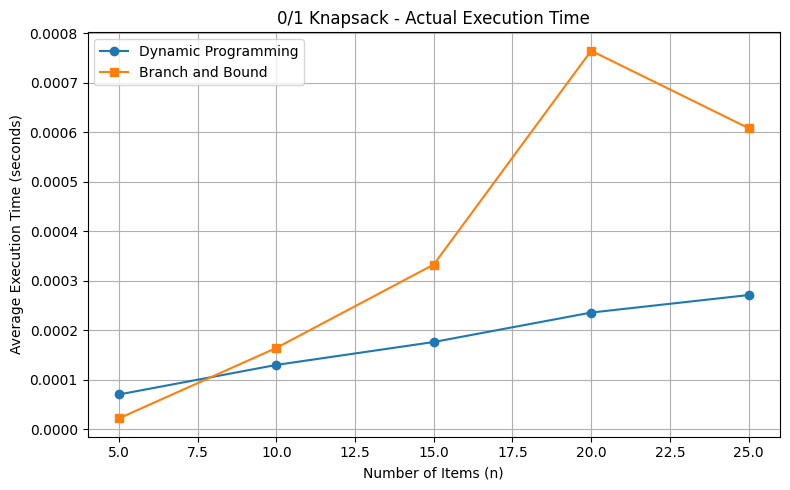

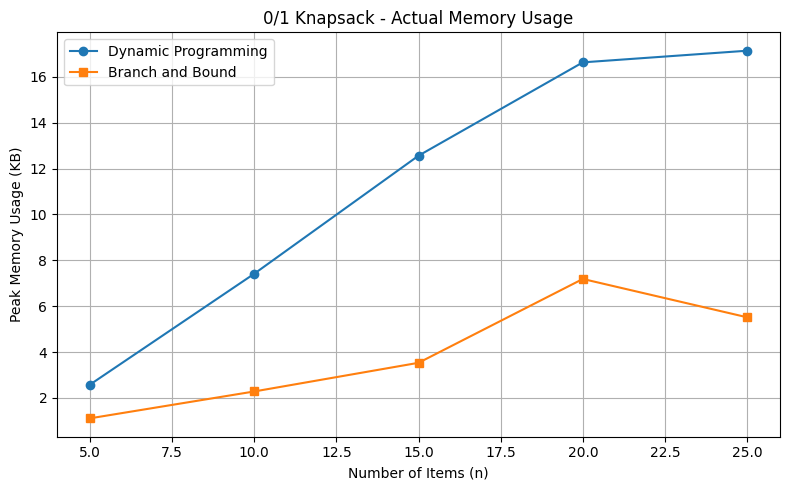

In [ ]:

from collections import deque
from time import perf_counter
import matplotlib.pyplot as plt
import statistics
import random
import tracemalloc

capacity = 50

# 1. Dynamic Programming
def dp_knapsack(weights, profits, capacity):
    n = len(weights)
    dp = [[0] * (capacity + 1) for _ in range(n + 1)]

    for i in range(1, n + 1):
        for w in range(capacity + 1):
            dp[i][w] = dp[i - 1][w]

            if weights[i - 1] <= w:
                dp[i][w] = max(
                    dp[i][w],
                    profits[i - 1] + dp[i - 1][w - weights[i - 1]]
                )

    return dp[n][capacity]


# 2. Branch and Bound
def bb_knapsack(weights, profits, capacity):
    items = sorted(
        zip(weights, profits),
        key=lambda item: item[1] / item[0],
        reverse=True
    )

    n = len(items)
    best = 0
    q = deque([(0, 0, 0)])

    def bound(i, p, w):
        total = p

        while i < n and w + items[i][0] <= capacity:
            w += items[i][0]
            total += items[i][1]
            i += 1

        if i < n:
            total += (capacity - w) * items[i][1] / items[i][0]

        return total

    while q:
        i, p, w = q.popleft()
        best = max(best, p)

        if i == n:
            continue

        wt, pr = items[i]

        if w + wt <= capacity:
            if bound(i + 1, p + pr, w + wt) > best:
                q.append((i + 1, p + pr, w + wt))

        if bound(i + 1, p, w) > best:
            q.append((i + 1, p, w))

    return best


# Measure actual execution time
def measure_time(function, *args):
    times = []

    for _ in range(3):
        start = perf_counter()

        for _ in range(5):
            function(*args)

        times.append((perf_counter() - start) / 5)

    return statistics.median(times)


# Measure actual peak memory in KB
def measure_memory(function, *args):
    values = []

    for _ in range(3):
        tracemalloc.start()

        try:
            function(*args)
            current, peak = tracemalloc.get_traced_memory()
        finally:
            tracemalloc.stop()

        values.append(peak / 1024)

    return statistics.median(values)


# Example
weights = [10, 20, 30]
profits = [60, 100, 120]

print("Maximum Profit (DP):",
      dp_knapsack(weights, profits, capacity))

print("Maximum Profit (B&B):",
      bb_knapsack(weights, profits, capacity))


# Generate fixed datasets for both algorithms
random.seed(10)

sizes = [5, 10, 15, 20, 25]
test_data = []

for n in sizes:
    weights = [random.randint(1, 20) for _ in range(n)]
    profits = [random.randint(10, 100) for _ in range(n)]
    test_data.append((weights, profits))


dp_times, bb_times = [], []
dp_memory, bb_memory = [], []

for n, (weights, profits) in zip(sizes, test_data):

    # Check that both algorithms return the same result
    dp_result = dp_knapsack(weights, profits, capacity)
    bb_result = bb_knapsack(weights, profits, capacity)

    print(f"\nn = {n}: DP = {dp_result}, B&B = {bb_result}")

    dp_times.append(
        measure_time(dp_knapsack, weights, profits, capacity)
    )

    bb_times.append(
        measure_time(bb_knapsack, weights, profits, capacity)
    )

    dp_memory.append(
        measure_memory(dp_knapsack, weights, profits, capacity)
    )

    bb_memory.append(
        measure_memory(bb_knapsack, weights, profits, capacity)
    )


# Display measured results
print("\nItems | DP Time    | B&B Time | DP Memory | B&B Memory")
for n, dt, bt, dm, bm in zip(
    sizes, dp_times, bb_times, dp_memory, bb_memory
):
    print(f"{n:5d} | {dt:.8f} | {bt:.8f} | {dm:.3f} KB | {bm:.3f} KB")


# Graph 1: Actual execution time
plt.figure(figsize=(8, 5))
plt.plot(sizes, dp_times, marker="o", label="Dynamic Programming")
plt.plot(sizes, bb_times, marker="s", label="Branch and Bound")

plt.xlabel("Number of Items (n)")
plt.ylabel("Average Execution Time (seconds)")
plt.title("0/1 Knapsack - Actual Execution Time")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# Graph 2: Actual peak memory
plt.figure(figsize=(8, 5))
plt.plot(sizes, dp_memory, marker="o", label="Dynamic Programming")
plt.plot(sizes, bb_memory, marker="s", label="Branch and Bound")

plt.xlabel("Number of Items (n)")
plt.ylabel("Peak Memory Usage (KB)")
plt.title("0/1 Knapsack - Actual Memory Usage")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



========== EXAMPLE DATASET ==========
Knapsack Capacity: 50
----------------------------------------
Item      Weight      Profit/Value   
----------------------------------------
1         10          60             
2         20          100            
3         30          120            
----------------------------------------
Maximum Profit (DP): 220
Maximum Profit (B&B): 220

========== GENERATED DATASETS ==========

Dataset for n = 5
Knapsack Capacity: 50
----------------------------------------
Item      Weight      Profit/Value   
----------------------------------------
1         19          11             
2         2           36             
3         14          69             
4         16          72             
5         19          45             
----------------------------------------

Dataset for n = 10
Knapsack Capacity: 50
----------------------------------------
Item      Weight      Profit/Value   
----------------------------------------
1         6      

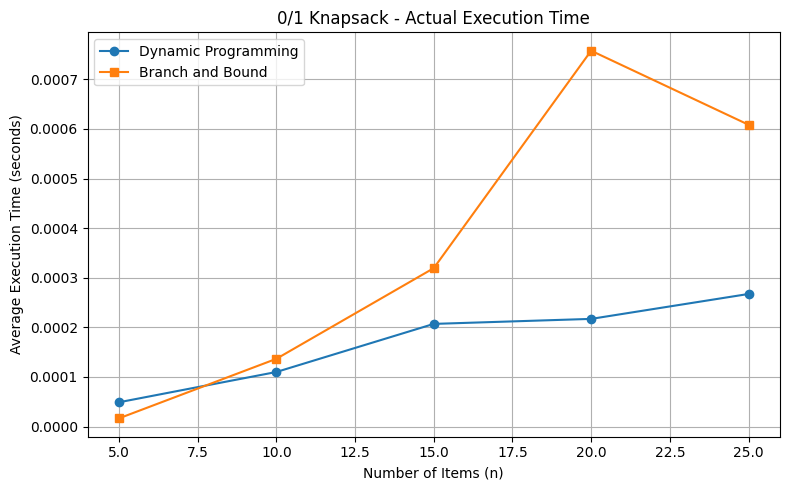

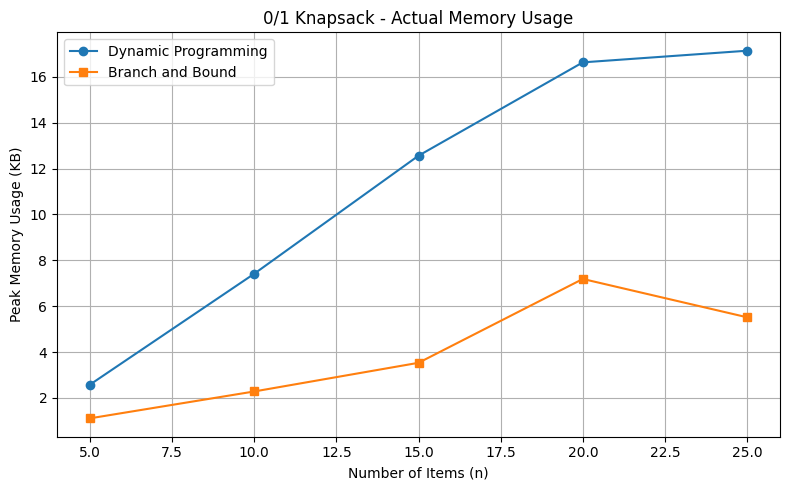

In [ ]:

from collections import deque
from time import perf_counter
import matplotlib.pyplot as plt
import statistics
import random
import tracemalloc

capacity = 50


# 1. Dynamic Programming
def dp_knapsack(weights, profits, capacity):
    n = len(weights)
    dp = [[0] * (capacity + 1) for _ in range(n + 1)]

    for i in range(1, n + 1):
        for w in range(capacity + 1):
            dp[i][w] = dp[i - 1][w]

            if weights[i - 1] <= w:
                dp[i][w] = max(
                    dp[i][w],
                    profits[i - 1] + dp[i - 1][w - weights[i - 1]]
                )

    return dp[n][capacity]


# 2. Branch and Bound
def bb_knapsack(weights, profits, capacity):
    items = sorted(
        zip(weights, profits),
        key=lambda item: item[1] / item[0],
        reverse=True
    )

    n = len(items)
    best = 0
    q = deque([(0, 0, 0)])

    def bound(i, p, w):
        total = p

        while i < n and w + items[i][0] <= capacity:
            w += items[i][0]
            total += items[i][1]
            i += 1

        if i < n:
            total += (capacity - w) * items[i][1] / items[i][0]

        return total

    while q:
        i, p, w = q.popleft()
        best = max(best, p)

        if i == n:
            continue

        wt, pr = items[i]

        # Include the current item
        if w + wt <= capacity:
            if bound(i + 1, p + pr, w + wt) > best:
                q.append((i + 1, p + pr, w + wt))

        # Exclude the current item
        if bound(i + 1, p, w) > best:
            q.append((i + 1, p, w))

    return best


# 3. Measure actual execution time
def measure_time(function, *args):
    times = []

    for _ in range(3):
        start = perf_counter()

        for _ in range(5):
            function(*args)

        times.append((perf_counter() - start) / 5)

    return statistics.median(times)


# 4. Measure actual peak memory in KB
def measure_memory(function, *args):
    values = []

    for _ in range(3):
        tracemalloc.start()

        try:
            function(*args)
            current, peak = tracemalloc.get_traced_memory()
        finally:
            tracemalloc.stop()

        values.append(peak / 1024)

    return statistics.median(values)


# 5. Display weights and profits
def display_items(weights, profits, capacity):
    print(f"Knapsack Capacity: {capacity}")
    print("-" * 40)
    print(f"{'Item':<10}{'Weight':<12}{'Profit/Value':<15}")
    print("-" * 40)

    for i in range(len(weights)):
        print(f"{i + 1:<10}{weights[i]:<12}{profits[i]:<15}")

    print("-" * 40)


# 6. Example dataset
example_weights = [10, 20, 30]
example_profits = [60, 100, 120]

print("\n========== EXAMPLE DATASET ==========")
display_items(example_weights, example_profits, capacity)

print("Maximum Profit (DP):",
      dp_knapsack(example_weights, example_profits, capacity))

print("Maximum Profit (B&B):",
      bb_knapsack(example_weights, example_profits, capacity))


# 7. Generate fixed datasets for both algorithms
random.seed(10)

sizes = [5, 10, 15, 20, 25]
test_data = []

for n in sizes:
    weights = [random.randint(1, 20) for _ in range(n)]
    profits = [random.randint(10, 100) for _ in range(n)]
    test_data.append((weights, profits))


# 8. Display every generated dataset
print("\n========== GENERATED DATASETS ==========")

for n, (weights, profits) in zip(sizes, test_data):
    print(f"\nDataset for n = {n}")
    display_items(weights, profits, capacity)


# 9. Compare execution time and memory
dp_times, bb_times = [], []
dp_memory, bb_memory = [], []

print("\n========== ALGORITHM COMPARISON ==========")

for n, (weights, profits) in zip(sizes, test_data):

    dp_result = dp_knapsack(weights, profits, capacity)
    bb_result = bb_knapsack(weights, profits, capacity)

    print(f"\nn = {n}")
    print("Maximum Profit (DP):", dp_result)
    print("Maximum Profit (B&B):", bb_result)

    if dp_result != bb_result:
        print("Warning: Results do not match!")

    dp_times.append(
        measure_time(dp_knapsack, weights, profits, capacity)
    )

    bb_times.append(
        measure_time(bb_knapsack, weights, profits, capacity)
    )

    dp_memory.append(
        measure_memory(dp_knapsack, weights, profits, capacity)
    )

    bb_memory.append(
        measure_memory(bb_knapsack, weights, profits, capacity)
    )


# 10. Display measured results
print("\n========== PERFORMANCE RESULTS ==========")
print(
    f"{'Items':<8}{'DP Time (s)':<16}{'B&B Time (s)':<16}"
    f"{'DP Memory (KB)':<18}{'B&B Memory (KB)':<18}"
)

for n, dt, bt, dm, bm in zip(
    sizes, dp_times, bb_times, dp_memory, bb_memory
):
    print(
        f"{n:<8}{dt:<16.8f}{bt:<16.8f}"
        f"{dm:<18.3f}{bm:<18.3f}"
    )


# 11. Graph 1: Actual execution time
plt.figure(figsize=(8, 5))

plt.plot(
    sizes, dp_times,
    marker="o",
    label="Dynamic Programming"
)

plt.plot(
    sizes, bb_times,
    marker="s",
    label="Branch and Bound"
)

plt.xlabel("Number of Items (n)")
plt.ylabel("Average Execution Time (seconds)")
plt.title("0/1 Knapsack - Actual Execution Time")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# 12. Graph 2: Actual peak memory
plt.figure(figsize=(8, 5))

plt.plot(
    sizes, dp_memory,
    marker="o",
    label="Dynamic Programming"
)

plt.plot(
    sizes, bb_memory,
    marker="s",
    label="Branch and Bound"
)

plt.xlabel("Number of Items (n)")
plt.ylabel("Peak Memory Usage (KB)")
plt.title("0/1 Knapsack - Actual Memory Usage")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
